# Distance-based features — meeting walkthrough

Two things in one notebook, since last time I didn't get to present on my phone:

| # | Section | Decision to discuss |
|---|---|---|
| 0 | Recap — how we cleaned HDB / MRT / Schools, and last meeting's result | already agreed — keep the three |
| 1 | New data — Shopping Malls & Hawker Centres (point-only, no join key) | usable how? |
| 2 | New features — 500&nbsp;m / 1&nbsp;km / 2&nbsp;km radius counts | which radius wins? |
| 3 | New features — nearest-distance, malls, hawker, CBD distance | keep or skip each? |
| 4 | Quick RMSE test of everything new | which ones make the cut |
| 5 | Summary & open questions | for discussion |

This is my assignment for this sprint: distance-based features. Last meeting we only tested a flat
1 km count for primary schools and MRT stations. This time: test a couple of radii, add a
nearest-distance version of each, and bring in the Shopping Malls table as a new amenity.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA, CLEANED, OUT = ROOT / "data", ROOT / "cleaned", ROOT / "outputs"
FIG_DIR = OUT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TARGET = "MONTHLY_RENT"
KEY = ["TOWN", "BLOCK", "STREET"]
CUT = pd.Timestamp("2024-01-01")

# same categorical identity as 04_consolidate_auxiliary_features.ipynb, extended with two more
# slots (validated together with node scripts/validate_palette.js from the dataviz skill)
COLOR_MRT = "#2a78d6"      # slot 1 (existing team convention)
COLOR_SCHOOL = "#eb6834"   # slot 2 (existing team convention)
COLOR_MALL = "#2e9e6b"     # slot 3 (new)
COLOR_CBD = "#7a5cc9"      # slot 4 (new)
COLOR_HAWKER = "#7a5cc9"   # reuses slot 4 -- CBD is a single reference point, never a colored series itself
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
GOOD, BAD = "seagreen", "crimson"   # matches 03_feature_rmse.ipynb's own delta chart


def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))


def lower_strip(df):
    out = df.copy()
    text = out.select_dtypes(include=["object", "string"]).columns
    out[text] = out[text].apply(lambda s: s.astype(str).str.strip().str.lower())
    return out


hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv")
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
schools = pd.read_csv(CLEANED / "sg_schools_cleaned.csv")
train = pd.read_csv(DATA / "train.csv")
print("hdb blocks:", hdb.shape, " mrt rows:", mrt.shape, " schools:", schools.shape, " train:", train.shape)

hdb blocks: (9464, 12)  mrt rows: (243, 10)  schools: (337, 27)  train: (150000, 11)


## 0. Recap — how we cleaned the data, and what we found last meeting

One part this time, since it's really one story: how each dataset was cleaned, and what that cleaning
let us test last meeting. Quick overview only; the full investigation for each is in `01_eda_hdb.ipynb`,
`01_eda_mrt.ipynb` and `01_eda_school.ipynb`.

**HDB blocks** (`sg-hdb-block.csv`, 9,464 rows)
- Joined onto train/test on lowercased `(TOWN, BLOCK, STREET)` — 100% match.
- The source uses `-1` as a sentinel for unknown `MAX_FLOOR` / `YEAR_COMPLETED`, not `NaN`. Replaced with real `NaN`.
- Exactly 11 blocks are missing both fields — all 11 turned out to be **SERS** sites (blocks slated for demolition/relocation), confirmed against three known SERS clusters, not a data bug.

In [2]:
print(f"SERS-flagged blocks (MISSING_BUILDING_INFO): {hdb['MISSING_BUILDING_INFO'].sum()}")
hdb.loc[hdb["MISSING_BUILDING_INFO"], ["TOWN", "STREET", "BLOCK"]].sort_values(["TOWN", "STREET"]).head(11)

SERS-flagged blocks (MISSING_BUILDING_INFO): 11


,TOWN,STREET,BLOCK
4113,clementi,west coast road,518
5391,clementi,west coast road,514
5525,clementi,west coast road,515
6501,clementi,west coast road,513
8238,clementi,west coast road,519
8244,clementi,west coast road,520
3400,geylang,macpherson lane,82
4385,queenstown,commonwealth drive,63
5550,queenstown,commonwealth drive,55
2859,queenstown,tanglin halt road,30


**Last meeting's test: dropping these 11 blocks from training didn't help.** The obvious move once
we saw incomplete rows was to just drop them — none of the 11 ever show up in the validation window
anyway, so it looked "free." The holdout said otherwise.

In [3]:
verdict = pd.read_csv(OUT / "feature_rmse_verdict.csv")
verdict[verdict["claim"].str.contains("SERS")]

,claim,lgb_delta,check
5,Keep the 11 SERS blocks in training,-2.487,supported (dropping BASE fit hurts)


**My assumption going in was wrong.** Since none of the 11 SERS blocks appear in validation, I expected
removing their 159 training rows to be a non-event for validation error. It cost **−2.49** on LightGBM
instead. Here's why — the 159 rows aren't lost in isolation, they're a real chunk of a specific, narrow
corner of the training data.

In [4]:
sers_blocks = hdb.loc[hdb["MISSING_BUILDING_INFO"], ["TOWN", "STREET", "BLOCK"]]


def _clean_rent_inline(df):
    # small local version -- the real clean_rent() (with MONTH_INDEX etc.) is built in section 4
    out = lower_strip(df)
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    out["RENT_APPROVAL_DATE"] = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    return out


fit_check = _clean_rent_inline(train)
fit_check = fit_check[fit_check["RENT_APPROVAL_DATE"] < CUT]
fit_check = fit_check.merge(hdb[["TOWN", "BLOCK", "STREET", "MISSING_BUILDING_INFO"]], on=KEY, how="left")
sers_fit = fit_check[fit_check["MISSING_BUILDING_INFO"] == True]

print(f"SERS rows in the fit window: {len(sers_fit)} of {len(fit_check):,} ({len(sers_fit)/len(fit_check):.2%})")
print("\nspread across towns:", sers_blocks["TOWN"].value_counts().to_dict())
print("\nFLAT_TYPE of SERS rows:")
print(sers_fit["FLAT_TYPE"].value_counts())
print(f"\nSERS lease years: {int(sers_fit['LEASE_COMMENCE_DATE'].min())}-{int(sers_fit['LEASE_COMMENCE_DATE'].max())}"
      f"   |   overall fit median lease year: {int(fit_check['LEASE_COMMENCE_DATE'].median())}")

# how big a share of their own narrow (town, flat type) corner are the SERS rows?
seg = fit_check[(fit_check["TOWN"] == "clementi") & (fit_check["FLAT_TYPE"] == "3-room")]
print(f"\nclementi 3-room rows: {len(seg)} total, {int(seg['MISSING_BUILDING_INFO'].sum())} of them SERS "
      f"({seg['MISSING_BUILDING_INFO'].mean():.1%})")

SERS rows in the fit window: 159 of 105,837 (0.15%)

spread across towns: {'clementi': 6, 'queenstown': 4, 'geylang': 1}

FLAT_TYPE of SERS rows:
FLAT_TYPE
3-room    149
4-room      9
2-room      1
Name: count, dtype: int64

SERS lease years: 1968-1986   |   overall fit median lease year: 1988

clementi 3-room rows: 2298 total, 115 of them SERS (5.0%)


**What this shows:** 78% of the SERS rows (124 of 159) are in Clementi, and 94% of them are `3-room`
flats with leases from 1968-1986 — among the oldest in the whole training set (overall median lease year is
1988). They're 5% of the *entire* "Clementi 3-room" training slice.

Removing them doesn't erase a prediction target — it erases part of what teaches the model how `TOWN`,
`FLAT_TYPE`, and `LEASE_COMMENCE_DATE` combine to set rent for old 3-room flats in Clementi specifically.
Clementi has plenty of *other* 3-room flats in validation that are not SERS sites — they still benefit from
whatever the model learned about "old 3-room Clementi flats" during training, so thinning that signal by 5%
hurts them too, even though no SERS block itself is ever scored.

One more wrinkle: this only holds when `MAX_FLOOR` is **not** in the model. Add `MAX_FLOOR`, and dropping
SERS barely matters (+0.32, i.e. flips slightly positive) — plausibly because `MAX_FLOOR` is `NaN` for
every SERS row by construction (that's *why* they're flagged), so once the model has a feature that's
missing exactly on the rows being removed, the extra town/lease signal they carried is mostly cancelled
out by how LightGBM handles that missingness. Net call is still the same either way: keep the rows, leave
`MAX_FLOOR` as `NaN` for them, don't drop anything.

**MRT stations** (`sg-mrt-stations.csv`)
- Parsed the line code and an interchange flag out of the station `CODE` (e.g. `ns10`, `cc1`).
- Kept `planned` stations in the cleaned table, but **excluded** them from any "within X km" count — they don't help anyone commute today.
- Matched to the same URA planning area / region as HDB and Schools, so all three auxiliary tables share one geography.

In [5]:
print(mrt["STATUS"].value_counts().to_string())
print("unique open station names:", mrt.loc[mrt["STATUS"].eq("open"), "NAME"].nunique())
print("rows flagged as an interchange:", int(mrt["IS_INTERCHANGE"].sum()),
      "-> unique interchange station names:",
      mrt.loc[mrt["STATUS"].eq("open") & mrt["IS_INTERCHANGE"], "NAME"].nunique())

STATUS
open       231
planned     12
unique open station names: 192
rows flagged as an interchange: 95 -> unique interchange station names: 44


**Schools** (`sg-schools.csv`, 337 rows)
- `seng kang` → `sengkang` (a genuine spelling variant the HDB crosswalk doesn't use).
- 4 schools labelled `PLANNING_AREA == "central"` (not a real URA area) were reassigned to the planning
  area of their **nearest MRT station**.
- MOE's own 4-zone region was replaced with the same URA 5-region system HDB/MRT use.
- This sprint we also fixed **coordinates** — see next cell. `MRT_STATIONS` / `BUS_LINES` (free text)
  were parsed too, but aren't used as model features.

**This sprint's fix — schools with copied/wrong coordinates.** While building distance features I
sanity-checked every school's coordinates against its own address and its nearest named MRT station. 8 came
up wrong or imprecise and were looked up by hand and corrected:

| School | Issue | Before (lat, lon) | After (lat, lon) |
|---|---|---|---|
| Methodist Girls' School (Primary) | Coordinates copied from the Paya Lebar campus (Hougang) | 1.3495, 103.8850 | 1.3329, 103.7826 |
| Methodist Girls' School (Secondary) | Same copy error, same address | 1.3510, 103.8851 | 1.3329, 103.7826 |
| Paya Lebar Methodist Girls' School (Primary) | Right campus, coordinates just imprecise | 1.3495, 103.8850 | 1.3505, 103.8851 |
| Paya Lebar Methodist Girls' School (Secondary) | Right campus, coordinates just imprecise | 1.3510, 103.8851 | 1.3508, 103.8855 |
| St. Anthony's Primary School | Coordinates copied from St. Anthony's Canossian Primary (Bedok) | 1.3347, 103.9412 | 1.3645, 103.7492 |
| St. Anthony's Canossian Primary School | Right campus, coordinates just imprecise | 1.3347, 103.9412 | 1.3343, 103.9411 |
| Outram Secondary School | `STREET` already lists the new Anchorvale (Sengkang) campus; coordinates were still the old York Hill campus, 13.6 km away | 1.2865, 103.8371 | 1.3980, 103.8910 |
| Tao Nan School | ~7 km off with no traceable cause | 1.2943, 103.8490 | 1.3050, 103.9113 |

One further look-alike pair — the two Gan Eng Seng schools, which *do* share a coordinate — was checked and
confirmed genuinely close together, not an error, so left as-is. Full detail (how each was found and why) is
in `01_eda_school.ipynb`, section 5e.

In [6]:
primary = schools[schools["MAINLEVEL_CODE"].str.contains("primary", na=False)]
secondary = schools[schools["MAINLEVEL_CODE"].str.contains("secondary", na=False)]
print(f"schools: {len(schools)}  (primary: {len(primary)}, secondary: {len(secondary)})")
print("coordinates flagged wrong before this sprint's fix, now corrected: 8  |  checked and left as-is: 2 (Gan Eng Seng)")

schools: 337  (primary: 179, secondary: 133)
coordinates flagged wrong before this sprint's fix, now corrected: 8  |  checked and left as-is: 2 (Gan Eng Seng)


**Putting it together — last meeting's overall result.**

**Split:** fit Jan 2021 – Dec 2023, validate Jan 2024 – Mar 2025.
**Baseline features:** floor area, lease-commence year, month index, town, flat type, flat model.
**Baseline RMSE:** LR \$657 · LightGBM \$496.4. Δ = RMSE(BASE) − RMSE(this set); positive = better.

Loading the holdout straight from `outputs/feature_rmse_holdout.csv` (written by `03_feature_rmse.ipynb`) — no need to refit anything to show it again.

In [7]:
holdout = pd.read_csv(OUT / "feature_rmse_holdout.csv")
holdout[["spec", "lr", "lgb", "d_lgb"]].round(3)

,spec,lr,lgb,d_lgb
0,BASE,657.122,496.366,0.000
1,+ MAX_FLOOR,656.270,496.153,0.213
2,+ YEAR_COMPLETED,657.115,497.209,-0.843
3,+ BUILDING_AGE_AT_RENT,657.630,498.465,-2.099
4,+ n_primary_within_1km,657.077,496.832,-0.466
5,+ n_mrt_within_1km,656.382,495.982,0.384
6,+ n_schools_total,657.040,497.365,-0.999
7,+ n_schools_primary,657.026,497.444,-1.078
8,+ n_schools_secondary,657.020,495.838,0.529
9,+ n_schools_government,657.017,498.053,-1.686


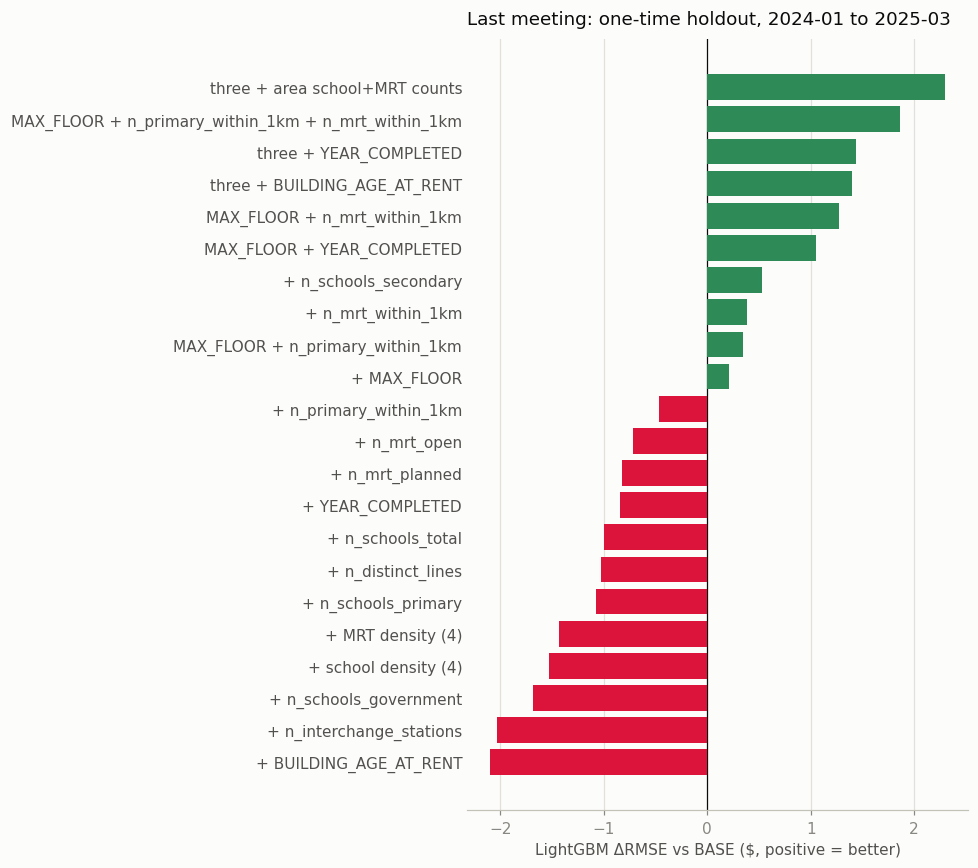

,claim,lgb_delta,check
0,Add MAX_FLOOR + n_primary_within_1km + n_mrt_w...,1.866,supported
1,Do not add YEAR_COMPLETED,-0.843,supported
2,Do not add BUILDING_AGE_AT_RENT,-2.099,supported
3,Do not add area-level school counts,-1.534,supported
4,Do not add area-level MRT counts,-1.438,supported
5,Keep the 11 SERS blocks in training,-2.487,supported (dropping BASE fit hurts)


In [8]:
plot = holdout[holdout["spec"] != "BASE"].sort_values("d_lgb")
fig, ax = plt.subplots(figsize=(9, 8))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
ax.barh(plot["spec"], plot["d_lgb"], color=np.where(plot["d_lgb"] >= 0, GOOD, BAD), zorder=3)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("LightGBM ΔRMSE vs BASE ($, positive = better)", color=INK_SECONDARY)
ax.set_title("Last meeting: one-time holdout, 2024-01 to 2025-03", color=INK, fontsize=12, loc="left", pad=10)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BASELINE)
ax.tick_params(axis="y", length=0, colors=INK_SECONDARY)
ax.tick_params(axis="x", colors=INK_MUTED)
ax.xaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_distance_features_recap.png", dpi=150, bbox_inches="tight")
plt.show()
verdict

**Key takeaways**

- **Keep:** `MAX_FLOOR`, `n_primary_within_1km`, `n_mrt_within_1km` together — beats BASE on LightGBM.
- **`YEAR_COMPLETED` / `BUILDING_AGE_AT_RENT`:** skip — both land *below* BASE on their own.
- **Area-level school/MRT totals** (`n_schools_total`, `n_mrt_open`, etc.): skip **on their own** — added
  alone to BASE they're worse than BASE, because `TOWN` already carries most of that signal (see the
  `singles` rows in `feature_rmse_holdout.csv`). Stacked *on top of* the three, they do add a little
  (`three + area school+MRT counts` row above) — but it's the smallest gain of anything we tested this
  sprint (section 4), smaller than any single new distance feature, so not worth the extra 8 columns for now.
- **Keep the 11 SERS rows in training** — see above.

Everything below builds on top of this — the three features above are the new baseline (call it
`REFERENCE`) that any new distance feature has to beat.

## 1. New data — Shopping Malls

`sg-shopping-malls.csv` is much thinner than the other three tables: **just `NAME`, `LATITUDE`,
`LONGITUDE`** — no address, no planning area, no postal code. That rules out an area-level feature
table like `mrt_features_by_area.csv` / `school_features_by_area.csv` — there's no key to group by.
The only thing we can do with it is **pure point-to-point distance**: nearest mall, or how many malls
sit within some radius of a block.

In [9]:
malls = pd.read_csv(DATA / "auxiliary" / "sg-shopping-malls.csv")
malls = lower_strip(malls)
print("shape:", malls.shape)
print("duplicate names:", malls["NAME"].duplicated().sum(),
      " duplicate coordinates:", malls.duplicated(["LATITUDE", "LONGITUDE"]).sum())
print("missing cells:", int(malls.isna().sum().sum()))
print("in Singapore's bounding box:",
      bool(malls["LATITUDE"].between(1.13, 1.47).all() and malls["LONGITUDE"].between(103.6, 104.1).all()))
malls.head(3)

shape: (113, 3)
duplicate names: 0  duplicate coordinates: 0
missing cells: 0
in Singapore's bounding box: True


,NAME,LATITUDE,LONGITUDE
0,alexandra retail centre,1.274,103.801
1,bugis junction,1.299,103.855
2,bugis+,1.298,103.856


113 malls, no missing cells, no duplicates, all inside Singapore's bounding box — clean enough to use as-is, no cleaning notebook needed for this one.

## 1b. New data — Hawker Centres

A teammate sourced `HawkerCentresGEOJSON.geojson` (NEA's `SSOT_HAWKERCENTRES` dataset) this sprint —
one of the "ideas for what else" from last time we actually got. It's a GeoJSON, not a CSV: each row is
a `Point` feature with a big properties block (address, stall count, construction status, even a photo
URL). Point-only again, like malls, but with a genuine `STATUS` field this time — worth checking before
just using every row.

In [10]:
import json

with open(DATA / "auxiliary" / "HawkerCentresGEOJSON.geojson") as f:
    hawker_raw = json.load(f)

hawker = pd.json_normalize([feat["properties"] for feat in hawker_raw["features"]])
hawker["LONGITUDE"] = [feat["geometry"]["coordinates"][0] for feat in hawker_raw["features"]]
hawker["LATITUDE"] = [feat["geometry"]["coordinates"][1] for feat in hawker_raw["features"]]
hawker = lower_strip(hawker)

print("shape:", hawker.shape)
print("STATUS values:\n", hawker["STATUS"].value_counts().to_string())
print("\nduplicate names:", hawker["NAME"].duplicated().sum(),
      " duplicate coordinates:", hawker.duplicated(["LATITUDE", "LONGITUDE"]).sum())
print("missing NAME/LATITUDE/LONGITUDE:", int(hawker[["NAME", "LATITUDE", "LONGITUDE"]].isna().sum().sum()))
print("in Singapore's bounding box:",
      bool(hawker["LATITUDE"].between(1.13, 1.47).all() and hawker["LONGITUDE"].between(103.6, 104.1).all()))
hawker[["NAME", "ADDRESSSTREETNAME", "STATUS", "NUMBER_OF_COOKED_FOOD_STALLS"]].head(3)

shape: (129, 22)
STATUS values:
 STATUS
existing                  103
existing (new)             16
under construction          6
existing (replacement)      3
interim centre              1

duplicate names: 0  duplicate coordinates: 0
missing NAME/LATITUDE/LONGITUDE: 0
in Singapore's bounding box: True


,NAME,ADDRESSSTREETNAME,STATUS,NUMBER_OF_COOKED_FOOD_STALLS
0,commonwealth crescent market,commonwealth crescent,existing,39
1,tiong bahru market,seng poh road,existing,83
2,golden mile food centre,beach road,existing,112


129 hawker centres, no missing names/coordinates, no duplicates, all in-bounds. `STATUS` has 6
values — the one that matters is **"Under Construction"** (6 rows): those aren't usable by residents yet,
same reasoning as excluding `planned` MRT stations. The rest (`Existing`, `Existing (new)`,
`Existing (replacement)`, `Interim Centre`) are all open today, so they count as "open" here.

In [11]:
hawker_open = hawker.loc[hawker["STATUS"] != "under construction", ["NAME", "LATITUDE", "LONGITUDE"]]
print(f"open hawker centres: {len(hawker_open)} of {len(hawker)}")

open hawker centres: 123 of 129


## 2. Building the distance features

One helper, reused for every amenity type: build the full block × amenity distance matrix once
(cheap — at most 9,464 × 337), then read off the nearest distance and three radius counts from it.

**Amenity groups:** primary schools, secondary schools, open MRT stations, open MRT *interchange*
stations, shopping malls, open hawker centres, and one single reference point for **distance to the CBD**
(Raffles Place MRT — a classic Singapore rent predictor, and free to add since we already have its
coordinates).

**Radii tested:** 500 m, 1 km (last meeting's choice), 2 km.

In [12]:
RADII_KM = {"500m": 0.5, "1km": 1.0, "2km": 2.0}


def poi_distance_features(hdb_lat, hdb_lon, poi_lat, poi_lon):
    d = haversine_km(hdb_lat[:, None], hdb_lon[:, None], poi_lat[None, :], poi_lon[None, :])
    out = {"nearest_km": d.min(axis=1)}
    for label, r in RADII_KM.items():
        out[f"within_{label}"] = (d <= r).sum(axis=1)
    return out


mrt_open = mrt.loc[mrt["STATUS"].eq("open"), ["NAME", "LATITUDE", "LONGITUDE"]].drop_duplicates("NAME")
mrt_interchange = mrt.loc[
    mrt["STATUS"].eq("open") & mrt["IS_INTERCHANGE"], ["NAME", "LATITUDE", "LONGITUDE"]
].drop_duplicates("NAME")
CBD_LAT, CBD_LON = mrt.loc[mrt["NAME"].eq("raffles place mrt station"), ["LATITUDE", "LONGITUDE"]].iloc[0]

POI_GROUPS = {
    "primary": primary,
    "secondary": secondary,
    "mrt": mrt_open,
    "mrt_interchange": mrt_interchange,
    "malls": malls,
    "hawker": hawker_open,
}

hdb_lat, hdb_lon = hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy()
for prefix, poi in POI_GROUPS.items():
    feats = poi_distance_features(hdb_lat, hdb_lon, poi["LATITUDE"].to_numpy(), poi["LONGITUDE"].to_numpy())
    for suffix, values in feats.items():
        hdb[f"{prefix}_{suffix}"] = values

hdb["dist_to_cbd_km"] = haversine_km(hdb_lat, hdb_lon, CBD_LAT, CBD_LON)
hdb["log_mrt_nearest_km"] = np.log1p(hdb["mrt_nearest_km"])

print(f"amenity counts used  ->  primary: {len(primary)}  secondary: {len(secondary)}  "
      f"open MRT: {len(mrt_open)}  MRT interchanges: {len(mrt_interchange)}  malls: {len(malls)}  "
      f"open hawker centres: {len(hawker_open)}")
new_cols = [c for c in hdb.columns if any(c.startswith(p + "_") for p in POI_GROUPS) or c.startswith("dist_to_cbd") or c.startswith("log_mrt")]
hdb[new_cols].describe().T.round(2)

amenity counts used  ->  primary: 179  secondary: 133  open MRT: 192  MRT interchanges: 44  malls: 113  open hawker centres: 123


,count,mean,std,min,25%,50%,75%,max
primary_nearest_km,"9,464.000",0.420,0.250,0.020,0.240,0.370,0.530,3.310
primary_within_500m,"9,464.000",0.990,0.810,0.000,0.000,1.000,1.000,4.000
primary_within_1km,"9,464.000",3.030,1.560,0.000,2.000,3.000,4.000,10.000
primary_within_2km,"9,464.000",8.420,3.510,0.000,6.000,8.000,10.000,20.000
secondary_nearest_km,"9,464.000",0.550,0.350,0.050,0.300,0.460,0.680,3.520
secondary_within_500m,"9,464.000",0.670,0.680,0.000,0.000,1.000,1.000,4.000
secondary_within_1km,"9,464.000",2.100,1.240,0.000,1.000,2.000,3.000,6.000
secondary_within_2km,"9,464.000",6.120,2.400,0.000,5.000,6.000,8.000,13.000
mrt_nearest_km,"9,464.000",0.630,0.340,0.020,0.390,0.570,0.800,2.570
mrt_within_500m,"9,464.000",0.440,0.560,0.000,0.000,0.000,1.000,5.000


## 3. Visualizing the new features

### 3a. How far is the nearest one, typically?

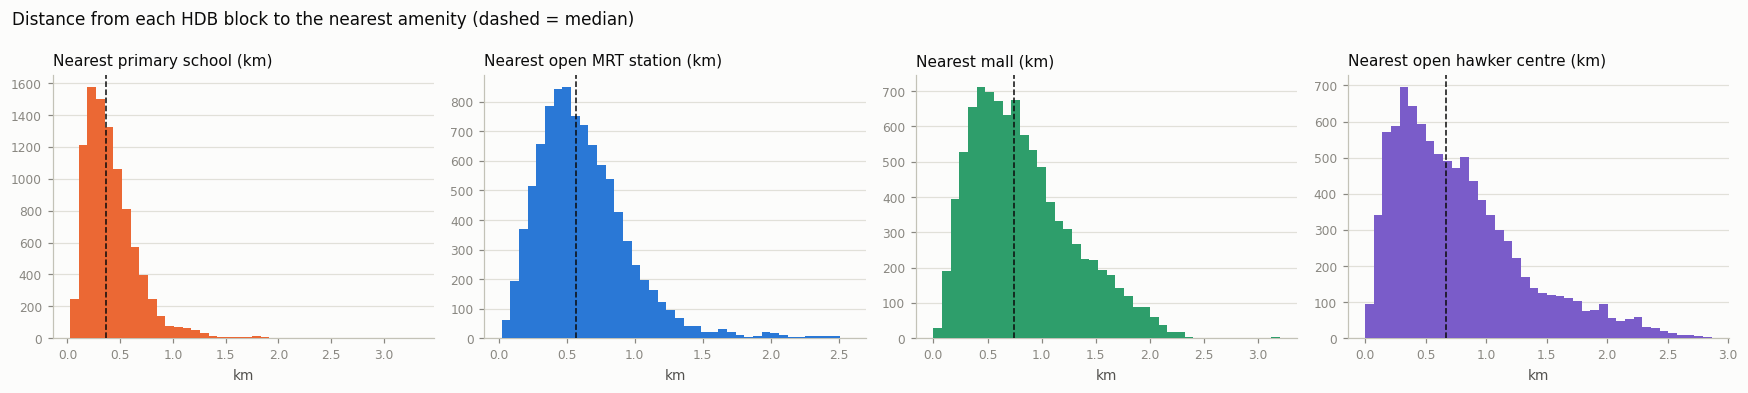

primary_nearest_km   0.365
mrt_nearest_km       0.568
malls_nearest_km     0.747
hawker_nearest_km    0.666
Name: median km, dtype: float64

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=False)
fig.patch.set_facecolor(SURFACE)
specs = [("primary_nearest_km", "Nearest primary school (km)", COLOR_SCHOOL),
         ("mrt_nearest_km", "Nearest open MRT station (km)", COLOR_MRT),
         ("malls_nearest_km", "Nearest mall (km)", COLOR_MALL),
         ("hawker_nearest_km", "Nearest open hawker centre (km)", COLOR_HAWKER)]
for ax, (col, title, c) in zip(axes, specs):
    ax.set_facecolor(SURFACE)
    ax.hist(hdb[col], bins=40, color=c, zorder=3)
    ax.axvline(hdb[col].median(), color=INK, lw=1, ls="--", zorder=4)
    ax.set_title(title, color=INK, fontsize=10, loc="left")
    ax.set_xlabel("km", color=INK_SECONDARY, fontsize=9)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE); ax.spines["left"].set_color(BASELINE)
    ax.tick_params(colors=INK_MUTED, labelsize=8)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
fig.suptitle("Distance from each HDB block to the nearest amenity (dashed = median)", color=INK, fontsize=11, x=0.01, ha="left")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_distance_features_nearest_hist.png", dpi=150, bbox_inches="tight")
plt.show()
hdb[["primary_nearest_km", "mrt_nearest_km", "malls_nearest_km", "hawker_nearest_km"]].median().rename("median km")

### 3b. Does a bigger radius actually pick up meaningfully more amenities?

The question this sprint is supposed to answer: is 1 km the right cut, or should we test 500 m / 2 km too?

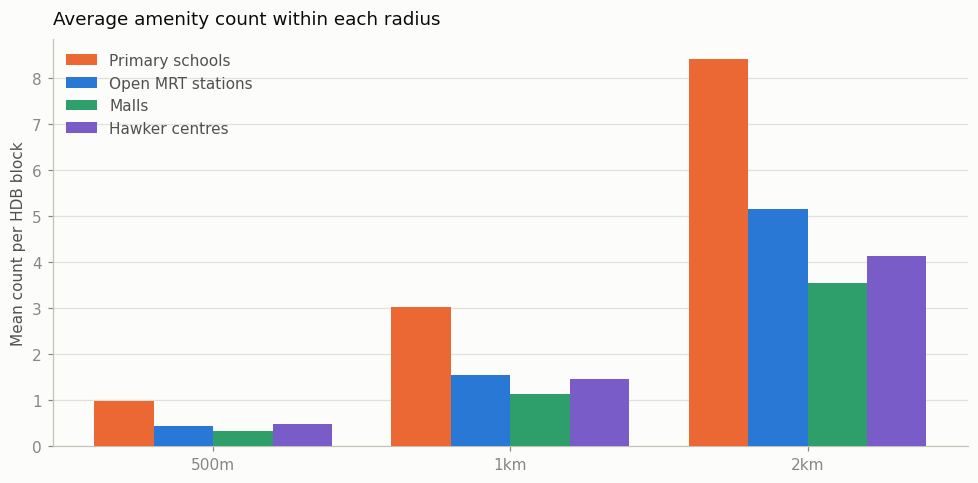

radius,1km,2km,500m
amenity,,,
Hawker centres,1.450,4.140,0.490
Malls,1.130,3.550,0.320
Open MRT stations,1.550,5.160,0.440
Primary schools,3.030,8.420,0.990


In [14]:
radius_summary = pd.DataFrame({
    "amenity": ["Primary schools"] * 3 + ["Open MRT stations"] * 3 + ["Malls"] * 3 + ["Hawker centres"] * 3,
    "radius": list(RADII_KM) * 4,
    "mean_count": [hdb[f"primary_within_{r}"].mean() for r in RADII_KM]
                 + [hdb[f"mrt_within_{r}"].mean() for r in RADII_KM]
                 + [hdb[f"malls_within_{r}"].mean() for r in RADII_KM]
                 + [hdb[f"hawker_within_{r}"].mean() for r in RADII_KM],
})

fig, ax = plt.subplots(figsize=(9, 4.5))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
amenity_colors = {"Primary schools": COLOR_SCHOOL, "Open MRT stations": COLOR_MRT, "Malls": COLOR_MALL, "Hawker centres": COLOR_HAWKER}
radii_order = list(RADII_KM)
x = np.arange(len(radii_order))
bar_w = 0.2
n_series = len(amenity_colors)
for i, (name, color) in enumerate(amenity_colors.items()):
    vals = radius_summary.loc[radius_summary["amenity"] == name].set_index("radius").loc[radii_order, "mean_count"]
    ax.bar(x + (i - (n_series - 1) / 2) * bar_w, vals, width=bar_w, color=color, label=name, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(radii_order, color=INK_SECONDARY)
ax.set_ylabel("Mean count per HDB block", color=INK_SECONDARY)
ax.set_title("Average amenity count within each radius", color=INK, fontsize=12, loc="left", pad=10)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BASELINE); ax.spines["left"].set_color(BASELINE)
ax.tick_params(colors=INK_MUTED)
ax.yaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left", labelcolor=INK_SECONDARY)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_distance_features_radius_compare.png", dpi=150, bbox_inches="tight")
plt.show()
radius_summary.pivot(index="amenity", columns="radius", values="mean_count").round(2)

500 m is sparse for all four (many blocks see 0 primary schools, 0 malls, or 0 hawker centres that
close — hawker centres in particular are built one per estate, not one per street). 2 km roughly triples
the school/MRT count and picks up malls and hawker centres that were essentially absent at 1 km. Whether
"more" is actually *better* for the model is a different question — that's what the RMSE test in
section 4 is for.

## 4. Quick RMSE test — same one-time holdout as last meeting

Same split (fit Jan 2021–Dec 2023, validate Jan 2024–Mar 2025), same two models. This time the
reference point isn't bare BASE — it's **`REFERENCE` = BASE + `MAX_FLOOR` + `n_primary_within_1km` +
`n_mrt_within_1km`**, i.e. everything already agreed on last meeting. The question for each row below
is: does this new feature earn its place *on top of* what we already decided to keep?

In [15]:
def clean_rent(df):
    out = lower_strip(df)
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    out["RENT_APPROVAL_DATE"] = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["MONTH_INDEX"] = (out["RENT_APPROVAL_DATE"].dt.year - 2021) * 12 + out["RENT_APPROVAL_DATE"].dt.month - 1
    return out.drop(columns=["FURNISHED", "FEE"], errors="ignore")


# rename to the exact names last meeting already used, so REFERENCE matches 03_feature_rmse.ipynb exactly
hdb_join = hdb.rename(columns={"primary_within_1km": "n_primary_within_1km", "mrt_within_1km": "n_mrt_within_1km"})
DIST_COLS = [c for c in hdb_join.columns if c not in [
    "TOWN", "BLOCK", "STREET", "POSTAL_CODE", "LATITUDE", "LONGITUDE",
    "MAX_FLOOR", "YEAR_COMPLETED", "SUBZONE", "PLANNING_AREA", "REGION", "MISSING_BUILDING_INFO",
]]

df = clean_rent(train).merge(hdb_join[KEY + ["MAX_FLOOR", "MISSING_BUILDING_INFO"] + DIST_COLS], on=KEY, how="left")
fit_df = df[df["RENT_APPROVAL_DATE"] < CUT].copy()
val_df = df[df["RENT_APPROVAL_DATE"] >= CUT].copy()
print(f"fit n={len(fit_df):,}   val n={len(val_df):,}")

BASE_NUM = ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "MONTH_INDEX"]
BASE_CAT = ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]
REFERENCE = ["MAX_FLOOR", "n_primary_within_1km", "n_mrt_within_1km"]


def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))


def fit_lr(f, v, extra):
    num, cat = BASE_NUM + [c for c in extra if c not in BASE_CAT], BASE_CAT
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    pipe = Pipeline([("pre", pre), ("m", LinearRegression())])
    pipe.fit(f[num + cat], f[TARGET])
    return rmse(v[TARGET], pipe.predict(v[num + cat]))


def fit_lgb(f, v, extra):
    cols = BASE_NUM + extra + BASE_CAT
    Xf, Xv = f[cols].copy(), v[cols].copy()
    for c in BASE_CAT:
        Xf[c] = Xf[c].astype("category")
        Xv[c] = pd.Categorical(Xv[c], categories=Xf[c].cat.categories)
    model = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, verbose=-1, n_jobs=-1, random_state=0)
    model.fit(Xf, f[TARGET], categorical_feature=BASE_CAT)
    return rmse(v[TARGET], model.predict(Xv))


def eval_spec(name, extra):
    return {"spec": name, "lr": fit_lr(fit_df, val_df, extra), "lgb": fit_lgb(fit_df, val_df, extra)}


reference = eval_spec("REFERENCE (last meeting's pick)", REFERENCE)
print(f"REFERENCE  LR={reference['lr']:.3f}  LightGBM={reference['lgb']:.3f}")

fit n=105,837   val n=44,163
REFERENCE  LR=655.574  LightGBM=494.501


### 4a. Does swapping the radius help?

In [16]:
RADIUS_SWAPS = [
    ("500m radius (schools+MRT)", ["MAX_FLOOR", "primary_within_500m", "mrt_within_500m"]),
    ("REFERENCE (1km, last meeting)", REFERENCE),
    ("2km radius (schools+MRT)", ["MAX_FLOOR", "primary_within_2km", "mrt_within_2km"]),
]
radius_rows = [eval_spec(n, e) for n, e in RADIUS_SWAPS]
radius_df = pd.DataFrame(radius_rows)
radius_df["d_lgb_vs_reference"] = reference["lgb"] - radius_df["lgb"]
radius_df[["spec", "lr", "lgb", "d_lgb_vs_reference"]]

,spec,lr,lgb,d_lgb_vs_reference
0,500m radius (schools+MRT),654.924,493.885,0.615
1,"REFERENCE (1km, last meeting)",655.574,494.501,0.000
2,2km radius (schools+MRT),655.034,493.530,0.970


**Malls and hawker centres weren't part of that test** — they were only ever tested at a fixed
1 km count (section 4b). Does the same 2 km-beats-1 km pattern hold for them too, or is it specific to
schools/MRT? Cheap to check — the 500 m/1 km/2 km columns already exist.

In [17]:
RADIUS_SWAPS_MALLS_HAWKER = [
    ("REFERENCE + malls/hawker @ 500m", REFERENCE + ["malls_within_500m", "hawker_within_500m"]),
    ("REFERENCE + malls/hawker @ 1km", REFERENCE + ["malls_within_1km", "hawker_within_1km"]),
    ("REFERENCE + malls/hawker @ 2km", REFERENCE + ["malls_within_2km", "hawker_within_2km"]),
]
radius_mh_rows = [eval_spec(n, e) for n, e in RADIUS_SWAPS_MALLS_HAWKER]
radius_mh_df = pd.DataFrame(radius_mh_rows)
radius_mh_df["d_lgb_vs_reference"] = reference["lgb"] - radius_mh_df["lgb"]
radius_mh_df[["spec", "lr", "lgb", "d_lgb_vs_reference"]]

,spec,lr,lgb,d_lgb_vs_reference
0,REFERENCE + malls/hawker @ 500m,655.017,493.304,1.197
1,REFERENCE + malls/hawker @ 1km,654.983,494.453,0.048
2,REFERENCE + malls/hawker @ 2km,655.056,493.665,0.836


**It does not generalize — malls/hawker actually prefer the opposite radius.** 500 m wins
(+1.20), 2 km is second (+0.84), and 1 km is the *worst* of the three here (+0.05, basically flat).
That's the reverse of schools/MRT, where 1 km was the worst and 2 km the best. Reading: a mall or
hawker centre is either practically on your doorstep or it isn't — a tight 500 m radius captures that
better than a wide one. Schools/MRT behave more like area-density signals, where a wider net reads the
neighbourhood better. **"Use 2 km" is not a blanket rule — it's specifically a schools/MRT finding.**

### 4b. New feature types, added on top of REFERENCE

In [18]:
NEW_SINGLES = [
    ("+ dist_nearest_primary_km", REFERENCE + ["primary_nearest_km"]),
    ("+ dist_nearest_mrt_km", REFERENCE + ["mrt_nearest_km"]),
    ("+ log1p(dist_nearest_mrt_km)", REFERENCE + ["log_mrt_nearest_km"]),
    ("+ n_secondary_within_1km", REFERENCE + ["secondary_within_1km"]),
    ("+ n_mrt_interchange_within_1km", REFERENCE + ["mrt_interchange_within_1km"]),
    ("+ dist_nearest_interchange_km", REFERENCE + ["mrt_interchange_nearest_km"]),
    ("+ n_malls_within_1km", REFERENCE + ["malls_within_1km"]),
    ("+ dist_nearest_mall_km", REFERENCE + ["malls_nearest_km"]),
    ("+ n_hawker_within_1km", REFERENCE + ["hawker_within_1km"]),
    ("+ dist_nearest_hawker_km", REFERENCE + ["hawker_nearest_km"]),
    ("+ dist_to_cbd_km", REFERENCE + ["dist_to_cbd_km"]),
]
singles_rows = [eval_spec(n, e) for n, e in NEW_SINGLES]
singles_df = pd.DataFrame(singles_rows)
singles_df["d_lgb_vs_reference"] = reference["lgb"] - singles_df["lgb"]
singles_df[["spec", "lr", "lgb", "d_lgb_vs_reference"]].sort_values("d_lgb_vs_reference", ascending=False)

,spec,lr,lgb,d_lgb_vs_reference
1,+ dist_nearest_mrt_km,654.273,492.234,2.267
2,+ log1p(dist_nearest_mrt_km),654.072,492.234,2.267
0,+ dist_nearest_primary_km,655.530,492.820,1.681
5,+ dist_nearest_interchange_km,654.912,492.946,1.555
7,+ dist_nearest_mall_km,654.472,493.385,1.116
6,+ n_malls_within_1km,655.078,493.442,1.059
9,+ dist_nearest_hawker_km,655.495,493.631,0.870
4,+ n_mrt_interchange_within_1km,655.327,493.700,0.801
10,+ dist_to_cbd_km,655.040,493.909,0.592
3,+ n_secondary_within_1km,655.550,494.234,0.267


### 4c. Combinations of the promising ones

In [19]:
COMBOS = [
    ("REFERENCE + malls (count + nearest)", REFERENCE + ["malls_within_1km", "malls_nearest_km"]),
    ("REFERENCE + hawker (count + nearest)", REFERENCE + ["hawker_within_1km", "hawker_nearest_km"]),
    ("REFERENCE + dist_to_cbd_km + malls_nearest_km", REFERENCE + ["dist_to_cbd_km", "malls_nearest_km"]),
    ("REFERENCE + nearest_primary + nearest_mrt", REFERENCE + ["primary_nearest_km", "mrt_nearest_km"]),
    ("REFERENCE + everything new (kitchen sink)", REFERENCE + [
        "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km", "mrt_interchange_within_1km",
        "mrt_interchange_nearest_km", "malls_within_1km", "malls_nearest_km",
        "hawker_within_1km", "hawker_nearest_km", "dist_to_cbd_km",
    ]),
    ("REFERENCE + kitchen sink minus bad hawker count", REFERENCE + [
        "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km", "mrt_interchange_within_1km",
        "mrt_interchange_nearest_km", "malls_within_1km", "malls_nearest_km",
        "hawker_nearest_km", "dist_to_cbd_km",
    ]),
]
combos_rows = [eval_spec(n, e) for n, e in COMBOS]
combos_df = pd.DataFrame(combos_rows)
combos_df["d_lgb_vs_reference"] = reference["lgb"] - combos_df["lgb"]
combos_df[["spec", "lr", "lgb", "d_lgb_vs_reference"]]

,spec,lr,lgb,d_lgb_vs_reference
0,REFERENCE + malls (count + nearest),654.458,492.131,2.370
1,REFERENCE + hawker (count + nearest),655.387,493.104,1.397
2,REFERENCE + dist_to_cbd_km + malls_nearest_km,653.997,492.765,1.735
3,REFERENCE + nearest_primary + nearest_mrt,654.270,491.551,2.949
4,REFERENCE + everything new (kitchen sink),652.659,489.968,4.533
5,REFERENCE + kitchen sink minus bad hawker count,652.693,490.312,4.189


### 4d. Everything on one chart

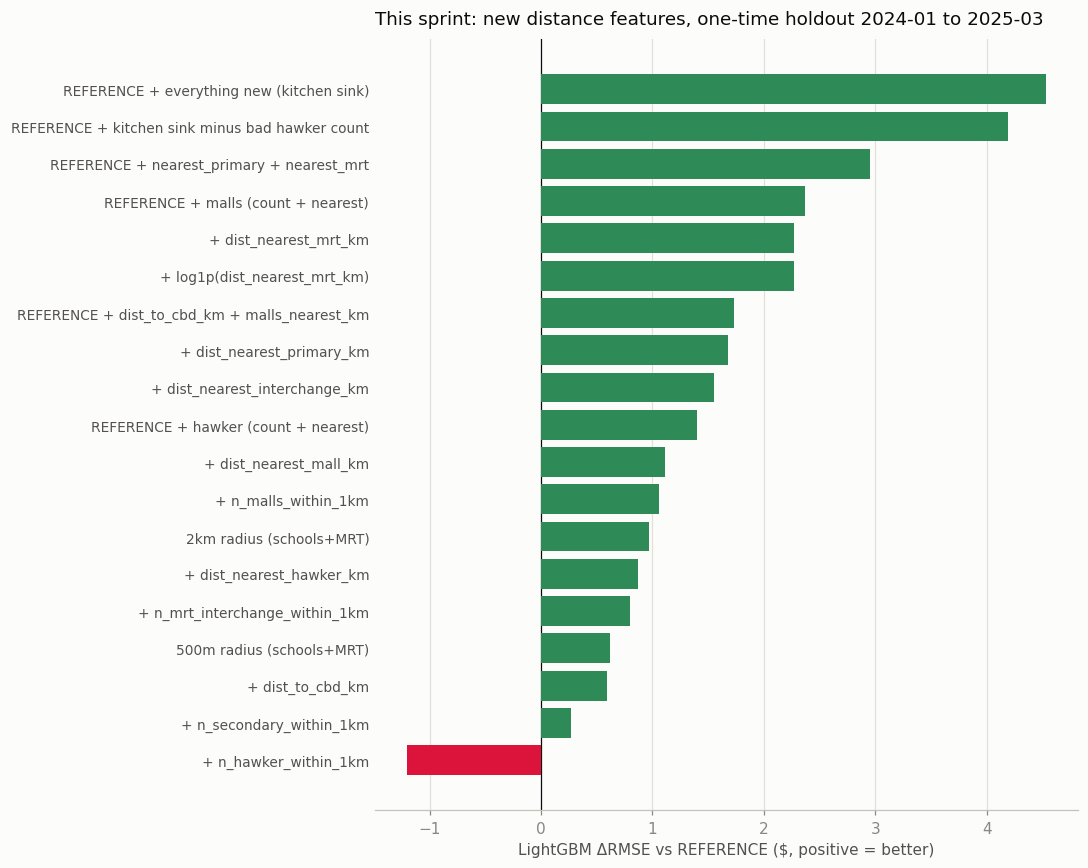

In [20]:
all_results = pd.concat([radius_df.iloc[[0, 2]], singles_df, combos_df], ignore_index=True)
all_results = all_results.sort_values("d_lgb_vs_reference")

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
ax.barh(all_results["spec"], all_results["d_lgb_vs_reference"],
        color=np.where(all_results["d_lgb_vs_reference"] >= 0, GOOD, BAD), zorder=3)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("LightGBM ΔRMSE vs REFERENCE ($, positive = better)", color=INK_SECONDARY)
ax.set_title("This sprint: new distance features, one-time holdout 2024-01 to 2025-03", color=INK, fontsize=12, loc="left", pad=10)
for s in ["top", "right", "left"]:
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color(BASELINE)
ax.tick_params(axis="y", length=0, colors=INK_SECONDARY, labelsize=9)
ax.tick_params(axis="x", colors=INK_MUTED)
ax.xaxis.grid(True, color=GRID, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(FIG_DIR / "06_distance_features_verdict.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
def flag(delta):
    if delta > 0.15:
        return "add"
    if delta < -0.15:
        return "skip"
    return "flat"


all_results["verdict"] = all_results["d_lgb_vs_reference"].map(flag)
holdout_out = pd.concat([radius_df, singles_df, combos_df], ignore_index=True)
holdout_out.to_csv(OUT / "distance_feature_rmse_holdout.csv", index=False)
all_results[["spec", "lgb", "d_lgb_vs_reference", "verdict"]].to_csv(OUT / "distance_feature_rmse_verdict.csv", index=False)
hdb.to_csv(OUT / "hdb_block_distance_features.csv", index=False)
print(f"wrote {OUT / 'distance_feature_rmse_holdout.csv'}, {OUT / 'distance_feature_rmse_verdict.csv'}, "
      f"{OUT / 'hdb_block_distance_features.csv'} ({hdb.shape})")
all_results[["spec", "lgb", "d_lgb_vs_reference", "verdict"]]

wrote ../outputs/distance_feature_rmse_holdout.csv, ../outputs/distance_feature_rmse_verdict.csv, ../outputs/hdb_block_distance_features.csv ((9464, 38))


,spec,lgb,d_lgb_vs_reference,verdict
10,+ n_hawker_within_1km,495.709,-1.208,skip
5,+ n_secondary_within_1km,494.234,0.267,add
12,+ dist_to_cbd_km,493.909,0.592,add
0,500m radius (schools+MRT),493.885,0.615,add
6,+ n_mrt_interchange_within_1km,493.700,0.801,add
11,+ dist_nearest_hawker_km,493.631,0.870,add
1,2km radius (schools+MRT),493.530,0.970,add
8,+ n_malls_within_1km,493.442,1.059,add
9,+ dist_nearest_mall_km,493.385,1.116,add
14,REFERENCE + hawker (count + nearest),493.104,1.397,add


### 4e. We kept testing everything on the 1 km REFERENCE — does the winning radius change that?

Every "add on top" test above (4b, 4c) still used `REFERENCE` = `n_primary_within_1km` +
`n_mrt_within_1km`, even though 4a showed 2 km beats 1 km for schools/MRT on its own — and the kitchen
sink itself still uses `malls_within_1km` / `hawker_within_1km`, even though the check above found
500 m wins for those two. Three variants: the current 1 km pick, swapping schools/MRT to 2 km, and
swapping schools/MRT to 2 km *and* malls/hawker to 500 m — each amenity at its own best radius.

In [22]:
REFERENCE_2KM = ["MAX_FLOOR", "primary_within_2km", "mrt_within_2km"]
KITCHEN_SINK_EXTRA = [
    "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km", "mrt_interchange_within_1km",
    "mrt_interchange_nearest_km", "malls_within_1km", "malls_nearest_km",
    "hawker_within_1km", "hawker_nearest_km", "dist_to_cbd_km",
]
KITCHEN_SINK_EXTRA_OPT = [
    "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km", "mrt_interchange_within_1km",
    "mrt_interchange_nearest_km", "malls_within_500m", "malls_nearest_km",
    "hawker_within_500m", "hawker_nearest_km", "dist_to_cbd_km",
]
radius_check = pd.DataFrame([
    eval_spec("1km REFERENCE + kitchen sink (current pick)", REFERENCE + KITCHEN_SINK_EXTRA),
    eval_spec("2km REFERENCE + kitchen sink", REFERENCE_2KM + KITCHEN_SINK_EXTRA),
    eval_spec("2km REFERENCE + kitchen sink, malls/hawker @ 500m", REFERENCE_2KM + KITCHEN_SINK_EXTRA_OPT),
])
radius_check["d_lgb_vs_reference"] = reference["lgb"] - radius_check["lgb"]
radius_check[["spec", "lr", "lgb", "d_lgb_vs_reference"]]

,spec,lr,lgb,d_lgb_vs_reference
0,1km REFERENCE + kitchen sink (current pick),652.659,489.968,4.533
1,2km REFERENCE + kitchen sink,652.441,489.576,4.925
2,"2km REFERENCE + kitchen sink, malls/hawker @ 500m",652.631,490.325,4.176


**Giving malls/hawker their own best radius (500 m) makes the full combo *worse*** (+4.18 vs +4.93) —
even though 500 m won when malls/hawker were tested in isolation, just alongside REFERENCE. Same lesson
as the hawker-count finding earlier: a radius (or a feature) that wins on its own doesn't always win once
it's interacting with everything else in the kitchen sink. **The actual best setting found this sprint:
2 km for schools/MRT, 1 km for malls/hawker, everything else stacked on top.**

## 5. Summary & open questions for the meeting

**Bottom line: switch schools/MRT to 2 km, keep malls/hawker at 1 km, stack everything.** Best combo beats BASE by **+6.79** total
(vs +1.87 from REFERENCE alone last meeting).

- **2 km beats 1 km — for schools and MRT specifically.** Malls/hawker actually prefer 500 m on their
  own, but keeping them at 1 km inside the full combo still beats giving them their own best radius
  (+4.93 vs +4.18) — so the recommendation is 2 km for schools/MRT, 1 km for malls/hawker, not "2 km
  for everything."
- **Nearest-distance beats plain counts** — `dist_nearest_mrt_km` alone is the strongest single new feature (+2.27).
- **Malls and CBD distance both help** (+2.37, +0.59).
- **Hawker centres:** count alone hurts (−1.21), but count + nearest-distance together help (+1.40).
- **Stack everything = best result:** +4.53 vs REFERENCE on 1 km, **+4.93 on 2 km** → +6.79 vs BASE overall.

**Caveats:** still one train/val split; malls (113) and hawker centres (123) are sparser than schools (337)
and MRT (231); distances are straight-line, not walking.

**Next idea if there's time:** parks / expressway distance — same "worth sourcing?" question hawker
centres were last time.